In [61]:
#importing libraries
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
#importing the dataset
df = pd.read_csv("breast-cancer-wisconsin.data", header=None)

In [8]:
#dataset information
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (699, 11)
Number of Rows: 699
Number of Columns: 11


In [9]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [11]:
#Reading the name file content using 'r' mode 
with open("breast-cancer-wisconsin.names", "r") as file:
    content = file.read()

print(content)

Citation Request:
   This breast cancer databases was obtained from the University of Wisconsin
   Hospitals, Madison from Dr. William H. Wolberg.  If you publish results
   when using this database, then please include this information in your
   acknowledgements.  Also, please cite one or more of:

   1. O. L. Mangasarian and W. H. Wolberg: "Cancer diagnosis via linear 
      programming", SIAM News, Volume 23, Number 5, September 1990, pp 1 & 18.

   2. William H. Wolberg and O.L. Mangasarian: "Multisurface method of 
      pattern separation for medical diagnosis applied to breast cytology", 
      Proceedings of the National Academy of Sciences, U.S.A., Volume 87, 
      December 1990, pp 9193-9196.

   3. O. L. Mangasarian, R. Setiono, and W.H. Wolberg: "Pattern recognition 
      via linear programming: Theory and application to medical diagnosis", 
      in: "Large-scale numerical optimization", Thomas F. Coleman and Yuying
      Li, editors, SIAM Publications, Philadelphia 199

In [12]:
#checking for the total number of missing values 

df.isnull().sum()

# there is none as the missing value is denoted in '?' 

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
dtype: int64

In [14]:
df[6].value_counts()
#checking the missing one '?' value count, found to be total of 16

6
1     402
10    132
2      30
5      30
3      28
8      21
4      19
?      16
9       9
7       8
6       4
Name: count, dtype: int64

In [26]:
#Assigning column names
columns = [
    "Sample_ID",
    "Clump_Thickness",
    "Uniformity_Cell_Size",
    "Uniformity_Cell_Shape",
    "Marginal_Adhesion",
    "Single_Epithelial_Cell_Size",
    "Bare_Nuclei",
    "Bland_Chromatin",
    "Normal_Nucleoli",
    "Mitoses",
    "Class"
]

df.columns = columns

In [27]:
df.head()

,Sample_ID,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Sample_ID                    699 non-null    int64
 1   Clump_Thickness              699 non-null    int64
 2   Uniformity_Cell_Size         699 non-null    int64
 3   Uniformity_Cell_Shape        699 non-null    int64
 4   Marginal_Adhesion            699 non-null    int64
 5   Single_Epithelial_Cell_Size  699 non-null    int64
 6   Bare_Nuclei                  683 non-null    str  
 7   Bland_Chromatin              699 non-null    int64
 8   Normal_Nucleoli              699 non-null    int64
 9   Mitoses                      699 non-null    int64
 10  Class                        699 non-null    int64
dtypes: int64(10), str(1)
memory usage: 60.2 KB


In [29]:
#Bare_Nuclei is stored as a string because of '?' can cause pandas issue so cnveer them to nummerical 

df["Bare_Nuclei"] = df["Bare_Nuclei"].replace("?", np.nan)

In [37]:
#convereting them to nummeric
df["Bare_Nuclei"] = pd.to_numeric(df["Bare_Nuclei"])

In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Sample_ID                    699 non-null    int64  
 1   Clump_Thickness              699 non-null    int64  
 2   Uniformity_Cell_Size         699 non-null    int64  
 3   Uniformity_Cell_Shape        699 non-null    int64  
 4   Marginal_Adhesion            699 non-null    int64  
 5   Single_Epithelial_Cell_Size  699 non-null    int64  
 6   Bare_Nuclei                  683 non-null    float64
 7   Bland_Chromatin              699 non-null    int64  
 8   Normal_Nucleoli              699 non-null    int64  
 9   Mitoses                      699 non-null    int64  
 10  Class                        699 non-null    int64  
dtypes: float64(1), int64(10)
memory usage: 60.2 KB


In [39]:
df.isnull().sum()

Sample_ID                       0
Clump_Thickness                 0
Uniformity_Cell_Size            0
Uniformity_Cell_Shape           0
Marginal_Adhesion               0
Single_Epithelial_Cell_Size     0
Bare_Nuclei                    16
Bland_Chromatin                 0
Normal_Nucleoli                 0
Mitoses                         0
Class                           0
dtype: int64

In [40]:
#checking for duplication 
df.duplicated().sum()

np.int64(8)

In [44]:
#checking if samplke id is repeated - becuase they might have different values byut same identifiers.
df["Sample_ID"].duplicated().sum()

np.int64(54)

In [46]:
df[df["Sample_ID"].duplicated(keep=False)].sort_values("Sample_ID")

,Sample_ID,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
267,320675,3,3,5,2,3,10.0,7,1,1,4
272,320675,3,3,5,2,3,10.0,7,1,1,4
269,385103,1,1,1,1,2,1.0,3,1,1,2
575,385103,5,1,2,1,2,1.0,3,1,1,2
607,411453,1,1,1,1,2,1.0,1,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...
560,1321942,5,1,1,1,2,1.0,3,1,1,2
661,1339781,4,1,1,1,2,1.0,3,1,1,2
660,1339781,1,1,1,1,2,1.0,2,1,1,2
673,1354840,5,3,2,1,3,1.0,1,1,1,2


In [48]:
#Exact duplicated rows is 8 and repeated data with different values (records) are 54
# Number of unique sample IDs
df["Sample_ID"].nunique()

645

In [49]:
# Number of rows belonging to repeated sample IDs
df["Sample_ID"].duplicated(keep=False).sum()

#100 is the number of rows belonging to repeated IDs, not the number of duplicate IDs.

np.int64(100)

In [51]:
# Number of repeated IDs that have conflicting measurements
duplicate_groups = df.groupby("Sample_ID")

conflicting_ids = []

for sample_id, group in duplicate_groups:

    unique_records = group.drop_duplicates()

    if len(unique_records) > 1:
        conflicting_ids.append(sample_id)

len(conflicting_ids)

39

In [53]:
#Data inspection task
#This is the target column

df["Class"].value_counts()

#2 = Benign,4 = Malignant

Class
2    458
4    241
Name: count, dtype: int64

In [54]:
df["Class"].value_counts(normalize=True) * 100

Class
2    65.522175
4    34.477825
Name: proportion, dtype: float64

In [55]:
feature_columns = [
    "Clump_Thickness",
    "Uniformity_Cell_Size",
    "Uniformity_Cell_Shape",
    "Marginal_Adhesion",
    "Single_Epithelial_Cell_Size",
    "Bare_Nuclei",
    "Bland_Chromatin",
    "Normal_Nucleoli",
    "Mitoses"
]

df[feature_columns].describe()

,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses
count,699.000000,699.000000,699.000000,699.000000,699.000000,683.000000,699.000000,699.000000,699.000000
mean,4.417740,3.134478,3.207439,2.806867,3.216023,3.544656,3.437768,2.866953,1.589413
std,2.815741,3.051459,2.971913,2.855379,2.214300,3.643857,2.438364,3.053634,1.715078
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000
50%,4.000000,1.000000,1.000000,1.000000,2.000000,1.000000,3.000000,1.000000,1.000000
75%,6.000000,5.000000,5.000000,4.000000,4.000000,6.000000,5.000000,4.000000,1.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


In [56]:
#Bare_Nuclei is missing 16 values
df[feature_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Clump_Thickness,699.0,4.417740,2.815741,1.0,2.0,4.0,6.0,10.0
Uniformity_Cell_Size,699.0,3.134478,3.051459,1.0,1.0,1.0,5.0,10.0
Uniformity_Cell_Shape,699.0,3.207439,2.971913,1.0,1.0,1.0,5.0,10.0
Marginal_Adhesion,699.0,2.806867,2.855379,1.0,1.0,1.0,4.0,10.0
Single_Epithelial_Cell_Size,699.0,3.216023,2.214300,1.0,2.0,2.0,4.0,10.0
Bare_Nuclei,683.0,3.544656,3.643857,1.0,1.0,1.0,6.0,10.0
Bland_Chromatin,699.0,3.437768,2.438364,1.0,2.0,3.0,5.0,10.0
Normal_Nucleoli,699.0,2.866953,3.053634,1.0,1.0,1.0,4.0,10.0
Mitoses,699.0,1.589413,1.715078,1.0,1.0,1.0,1.0,10.0


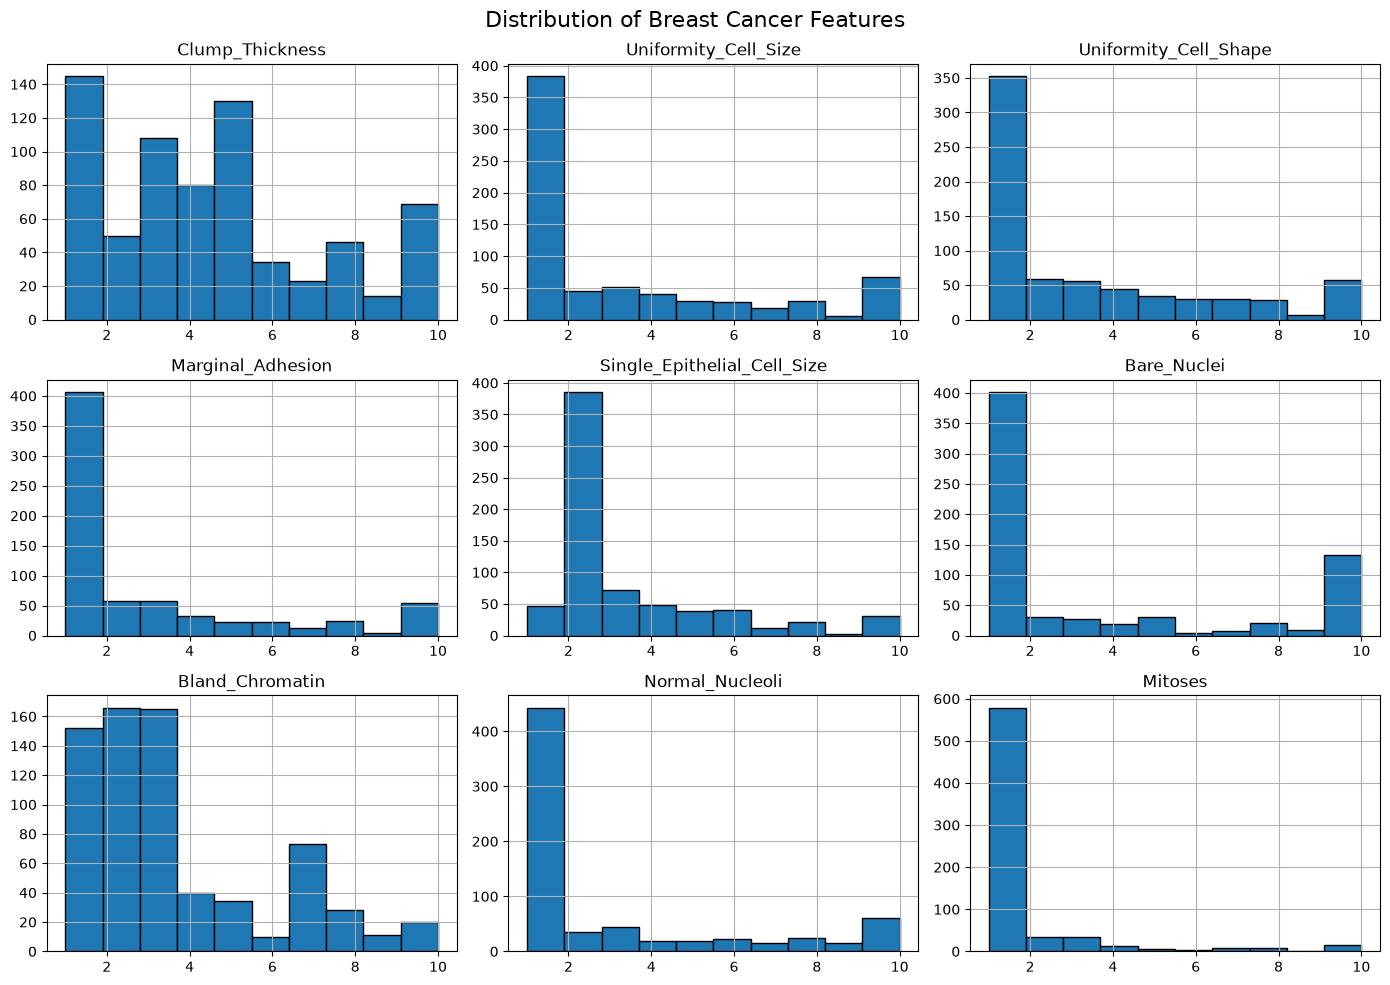

In [60]:
#Visualising feature distributions
df[feature_columns].hist(
    figsize=(14, 10),
    bins=10,
    edgecolor="black"
)

plt.suptitle("Distribution of Breast Cancer Features", fontsize=16)
plt.tight_layout()
plt.show()

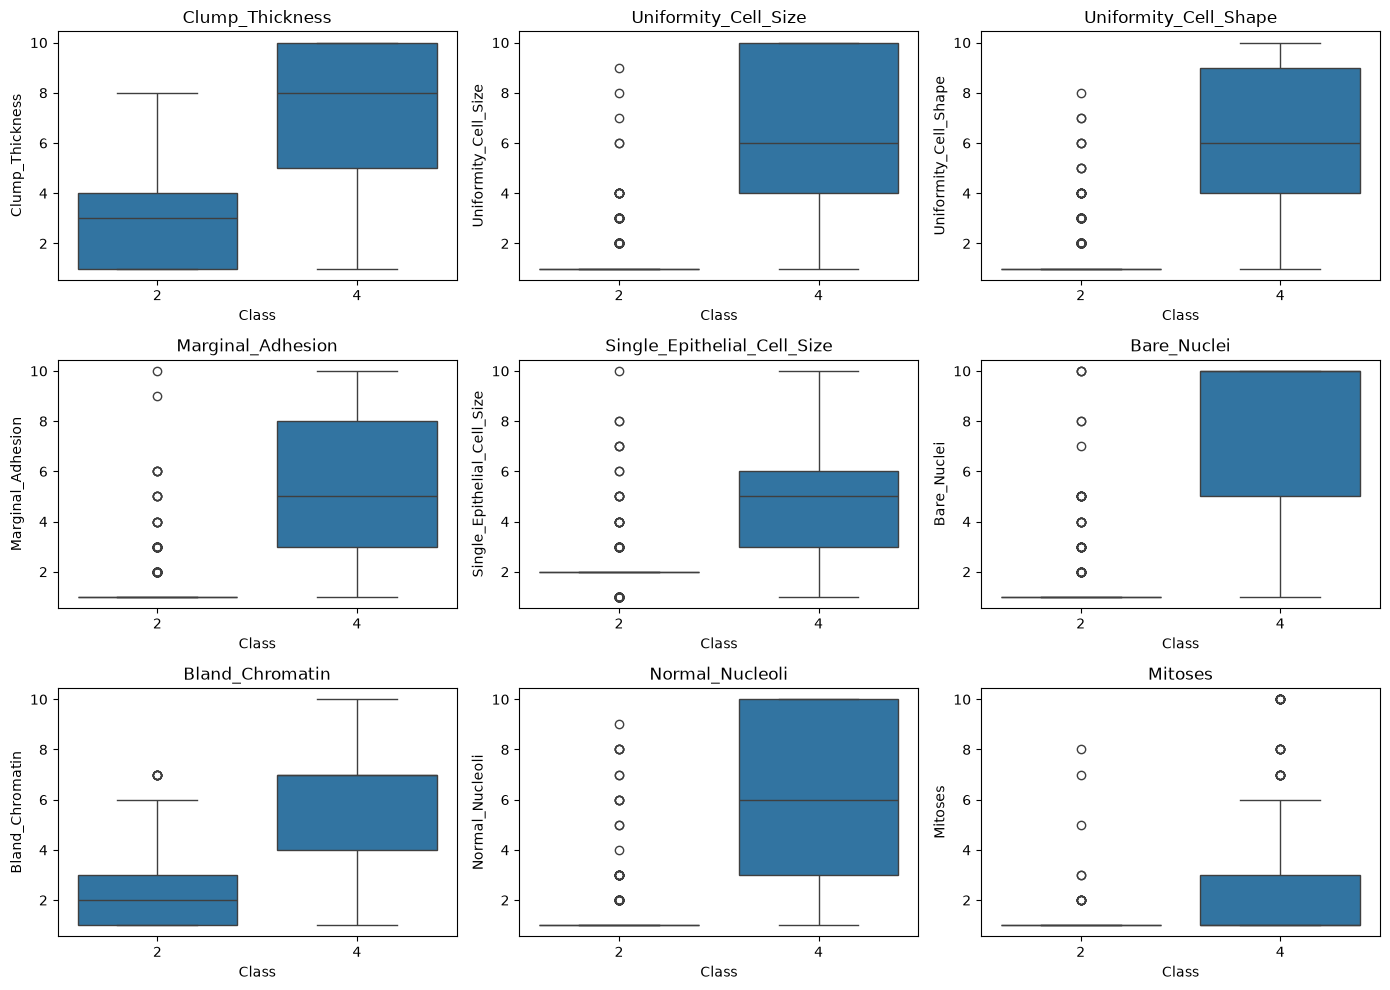

In [63]:
#relationship between features and diagnosis
plt.figure(figsize=(14, 10))

for i, feature in enumerate(feature_columns, 1):
    plt.subplot(3, 3, i)

    sns.boxplot(
        data=df,
        x="Class",
        y=feature
    )

    plt.title(feature)

plt.tight_layout()
plt.show()

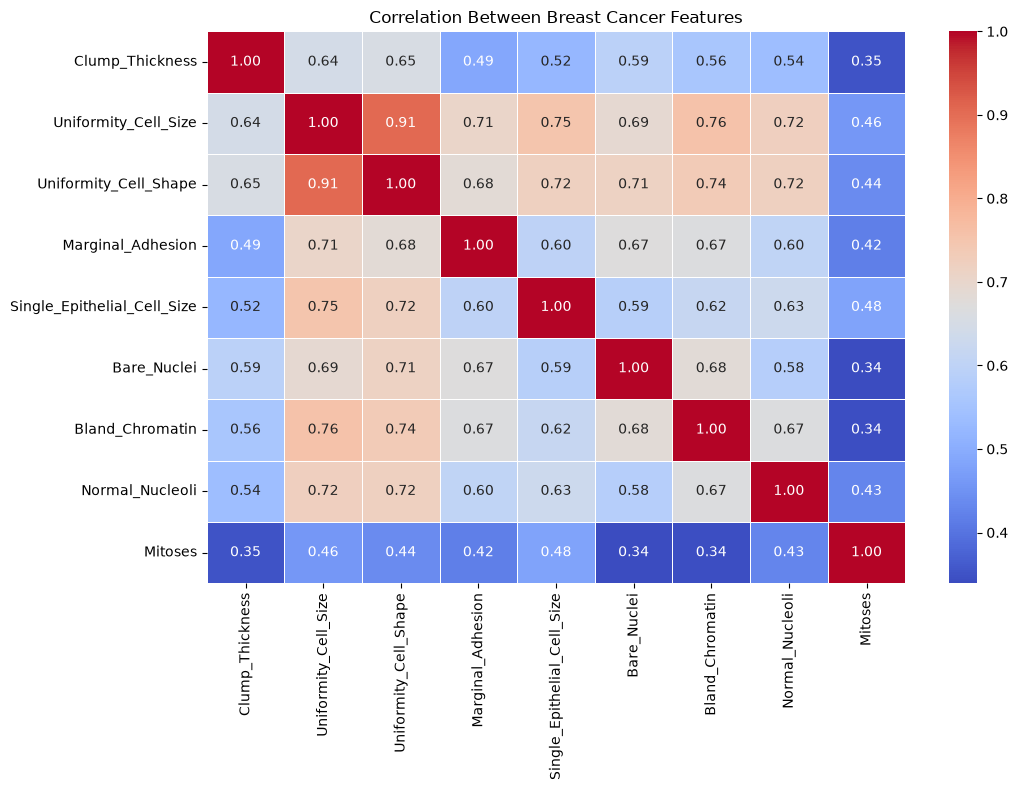

In [64]:
#In the above observation mitosis is seems to be less infomative because boht the class that it lies is less.

#heatmap to see the  correlation between features
correlation_matrix = df[feature_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Breast Cancer Features")
plt.tight_layout()
plt.show()

In [65]:
#check for repeated Sample_IDs have different class labels.
class_conflicts = df.groupby("Sample_ID")["Class"].nunique()

class_conflicts[class_conflicts > 1]

Sample_ID
695091     2
1171710    2
1198641    2
1299596    2
Name: Class, dtype: int64

In [67]:
conflicting_sample_ids = class_conflicts[class_conflicts > 1].index

df[df["Sample_ID"].isin(conflicting_sample_ids)].sort_values("Sample_ID").T

,577,691,109,108,258,266,168,467,644
Sample_ID,695091.0,695091.0,1171710.0,1171710.0,1198641.0,1198641.0,1198641.0,1299596.0,1299596.0
Clump_Thickness,1.0,5.0,6.0,1.0,3.0,10.0,3.0,6.0,2.0
Uniformity_Cell_Size,1.0,10.0,5.0,1.0,1.0,10.0,1.0,6.0,1.0
Uniformity_Cell_Shape,1.0,10.0,4.0,1.0,1.0,6.0,1.0,6.0,1.0
Marginal_Adhesion,1.0,5.0,4.0,1.0,1.0,3.0,1.0,5.0,1.0
Single_Epithelial_Cell_Size,2.0,4.0,3.0,2.0,2.0,3.0,2.0,4.0,2.0
Bare_Nuclei,1.0,5.0,9.0,1.0,1.0,10.0,1.0,10.0,1.0
Bland_Chromatin,2.0,4.0,7.0,2.0,3.0,4.0,3.0,7.0,1.0
Normal_Nucleoli,1.0,4.0,8.0,3.0,1.0,3.0,1.0,6.0,1.0
Mitoses,1.0,1.0,3.0,1.0,1.0,2.0,1.0,2.0,1.0


In [ ]:
#As i don't know whether the repeated IDs represent repeated observations or an identifier issue,Removing them without understanding their origin could discard useful information.
#i cannot confidently decide which class label is correct using the dataset alone.
# So i will document these four conflicting IDs as an unresolved source-data inconsistency.

In [68]:
print("Original shape:", df.shape)

df_no_exact_duplicates = df.drop_duplicates()

print("Shape after removing exact duplicates:",
      df_no_exact_duplicates.shape)

print("Rows removed:",
      df.shape[0] - df_no_exact_duplicates.shape[0])


Original shape: (699, 11)
Shape after removing exact duplicates: (691, 11)
Rows removed: 8
